## Task 1 — Explore the Dataset
Iris contains flowers from three species. Each flower has four measurements in cm: sepal length, sepal width, petal length, and petal width. Sepals are the outer flower parts; petals are the inner flower parts. The target label identifies the species.

Run the small steps below in order. Complete four short fill-in activities: load the data, preview its rows, and choose the two axis columns in each scatter plot. Other setup and plotting code is provided.

### 1.1 Import Basic Libraries
`numpy` supports array operations, `pandas` organizes data in tables, and `matplotlib.pyplot` draws plots. `display` shows tables in Jupyter. Run this cell first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

### 1.2 Load Iris Dataset
Load the built-in dataset with `load_iris()`. It contains measurements, numerical labels, feature names, and class names. Numerical labels identify categories; they do not represent an order between species.

**Hint:** call the loader imported at the top of the next cell. Fill in only the function name.

In [2]:

from sklearn.datasets import load_iris

iris = load_iris()
feature_names = iris.feature_names
class_names = iris.target_names

print('Measurement array shape:', iris.data.shape)
print('Label array shape:', iris.target.shape)
print('Feature names:', feature_names)
print('Class names:', class_names)


Measurement array shape: (150, 4)
Label array shape: (150,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Class names: ['setosa' 'versicolor' 'virginica']


### 1.3 Inspect the Data
Create a table with one flower per row. The four measurement columns are numeric inputs; `species` is the class name. Inspect the first five rows, class counts, and summary statistics.

In `describe()`, `mean` is the average, `std` is the sample standard deviation, and `min`/`max` give the observed range.

**Hint:** the DataFrame method `.head()` displays its first five rows by default. Fill in the method name.

In [6]:
iris_df = pd.DataFrame(data=iris.data, columns=feature_names)
print(iris_df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [7]:

data = pd.DataFrame(iris.data, columns=feature_names)
data['species'] = iris.target_names[iris.target]

print('First five flowers:')
display(data.head())

print('Flowers in each class:')
display(data['species'].value_counts())

print('Summary statistics for all four features:')
display(data[feature_names].describe())


First five flowers:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Flowers in each class:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Summary statistics for all four features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 1.4 Explore Sepal Features
Compare sepal length and sepal width across species. Inspect the mean measurements for each species, then examine the scatter plot. Each point represents one flower; color indicates its species. The axes use feature columns 0 and 1.

Look for overlap. Different species averages do not guarantee that every individual flower can be separated.

**Hint:** feature order is sepal length, sepal width, petal length, petal width. Column indices start at 0. Fill in the x-axis and y-axis indices in `ax.scatter`.

Mean sepal measurements by species:


,sepal length (cm),sepal width (cm)
species,,
setosa,5.006,3.428
versicolor,5.936,2.770
virginica,6.588,2.974


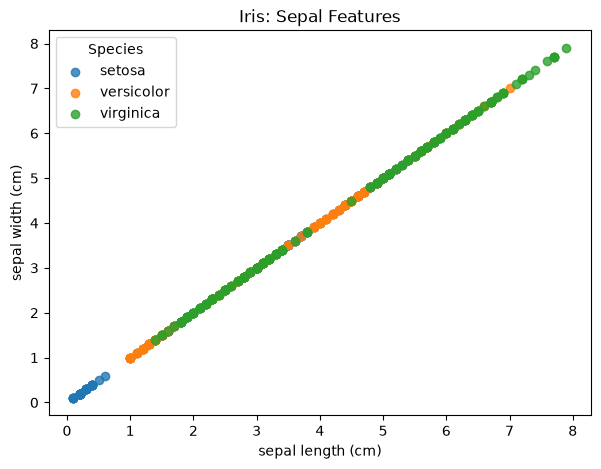

Mean sepal measurements by species:


,sepal length (cm),sepal width (cm)
species,,
setosa,5.006,3.428
versicolor,5.936,2.770
virginica,6.588,2.974


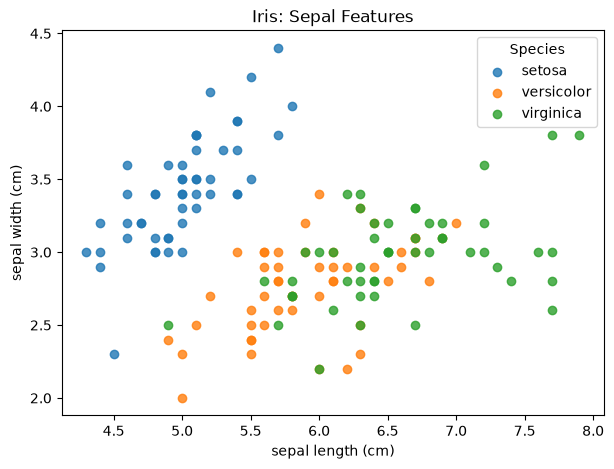

In [8]:
sepal_features = feature_names[:2]
print('Mean sepal measurements by species:')
display(data.groupby('species')[sepal_features].mean())

fig, ax = plt.subplots(figsize=(7, 5))
for label, name in enumerate(class_names):
    mask = iris.target == label
    ax.scatter(iris.data[mask, ...], iris.data[mask, ...],  # TODO: sepal column indices
               label=name, alpha=0.8)
ax.set(xlabel=feature_names[0], ylabel=feature_names[1],
       title='Iris: Sepal Features')
ax.legend(title='Species')
plt.show()
sepal_features = feature_names[:2]

print('Mean sepal measurements by species:')
display(data.groupby('species')[sepal_features].mean())

fig, ax = plt.subplots(figsize=(7, 5))

for label, name in enumerate(class_names):
    mask = iris.target == label
    ax.scatter(
        iris.data[mask, 0],
        iris.data[mask, 1],
        label=name,
        alpha=0.8
    )

ax.set(
    xlabel=feature_names[0],
    ylabel=feature_names[1],
    title='Iris: Sepal Features'
)
ax.legend(title='Species')
plt.show()


### 1.5 Explore Petal Features
Repeat the exploration for petal length and petal width, using feature columns 2 and 3. Compare the class overlap with the sepal plot. Read the axis scales: the two plots show different measurements.

**Hint:** use the same feature order as in Step 1.4. Fill in the x-axis and y-axis indices in `ax.scatter`.

Mean petal measurements by species:


,petal length (cm),petal width (cm)
species,,
setosa,1.462,0.246
versicolor,4.260,1.326
virginica,5.552,2.026


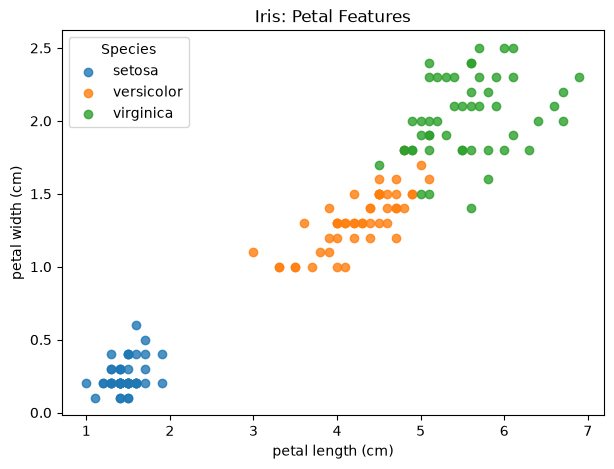

In [9]:

petal_features = feature_names[2:]

print('Mean petal measurements by species:')
display(data.groupby('species')[petal_features].mean())

fig, ax = plt.subplots(figsize=(7, 5))

for label, name in enumerate(class_names):
    mask = iris.target == label
    ax.scatter(
        iris.data[mask, 2],
        iris.data[mask, 3],
        label=name,
        alpha=0.8
    )

ax.set(
    xlabel=feature_names[2],
    ylabel=feature_names[3],
    title='Iris: Petal Features'
)
ax.legend(title='Species')
plt.show()


### 1.6 Compare Sepal and Petal Features
Use both scatter plots and summary tables to answer Question 1. Visual exploration helps you form a hypothesis about useful features. It does not replace validation of a trained classifier. The following tasks use all four measurements.

This data overview is provided for familiarization in an introductory lab. Keep the later split fixed. Do not use final test results to select features, parameters, or models.

### Question 1
**a. Understanding the table:** What does one row represent? What are the roles of the four measurement features and the `species` column?

**b. Comparing the plots:** Which feature pair, Sepal Features or Petal Features, appears more useful for distinguishing species? Explain using class overlap.

**Your answer:**

[Write your answer here.]

### Model Tools for the Following Tasks
Import the functions used later for data splitting, decision-tree training, visualization, and Accuracy evaluation. Step 1.1 imported the basic exploration libraries separately.

In [10]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

## Task 2 — Define inputs and split the data
Complete the input and label assignments. First reserve 20% (30 flowers) as the final test set. Split the remaining 80% development set into training and validation subsets (90 and 30 flowers). Tasks 3–6 use these subsets. Task 7 uses all 120 development flowers for cross-validation. Keep the test set untouched until Task 8. `stratify` preserves class proportions. Use training data to learn, validation data to choose parameters, and test data only after model selection.

**Code hint T2:** `iris.data` stores measurements; `iris.target` stores species labels.

In [11]:

X = iris.data
y = iris.target

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev
)

print('Training:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)


Training: (90, 4) Validation: (30, 4) Test: (30, 4)


### Question 2
What are the roles of the training, validation, and final test sets? Why should you avoid selecting parameters using the final test results?

**Your answer:**

[Write your answer here.]

## Evaluation with Accuracy
**Accuracy = number of correct predictions / total number of predictions.**

Accuracy ranges from 0 to 1; higher is better. The Iris dataset has 50 flowers in each of its three classes. In this introductory lab, Accuracy is the only prediction-performance metric.

Compare training and validation Accuracy in Tasks 3–6. During Grid Search, select by **mean cross-validation Accuracy**. Also compare actual tree depth and leaf count: models with equal Accuracy may have different structures and complexity. Small score differences do not necessarily establish that one model is clearly better.

## Task 3 — Create, train, and evaluate a baseline
Use Gini impurity and maximum depth 2.

**Code hint T3:** `DecisionTreeClassifier(criterion=..., max_depth=..., random_state=42)`; `.fit(features, labels)` learns from training data; `.predict(features)` returns predictions. `accuracy_score(true_labels, predicted_labels)` evaluates them.

In [12]:

baseline = DecisionTreeClassifier(
    criterion='gini',
    max_depth=2,
    random_state=42
)

baseline.fit(X_train, y_train)

val_pred = baseline.predict(X_val)

print('Training accuracy:', baseline.score(X_train, y_train))
print('Validation accuracy:', accuracy_score(y_val, val_pred))


Training accuracy: 0.9888888888888889
Validation accuracy: 0.9


## Task 4 — Visualize and follow the tree
A condition sends a sample left when true (`<=`) and right when false (`>`). `samples` is the number of training samples at a node. `value` shows class counts with this default unweighted configuration; `class` is the predicted species. Impurity is zero for a pure node.

**Code hint T4:** pass the trained classifier to `plot_tree`.

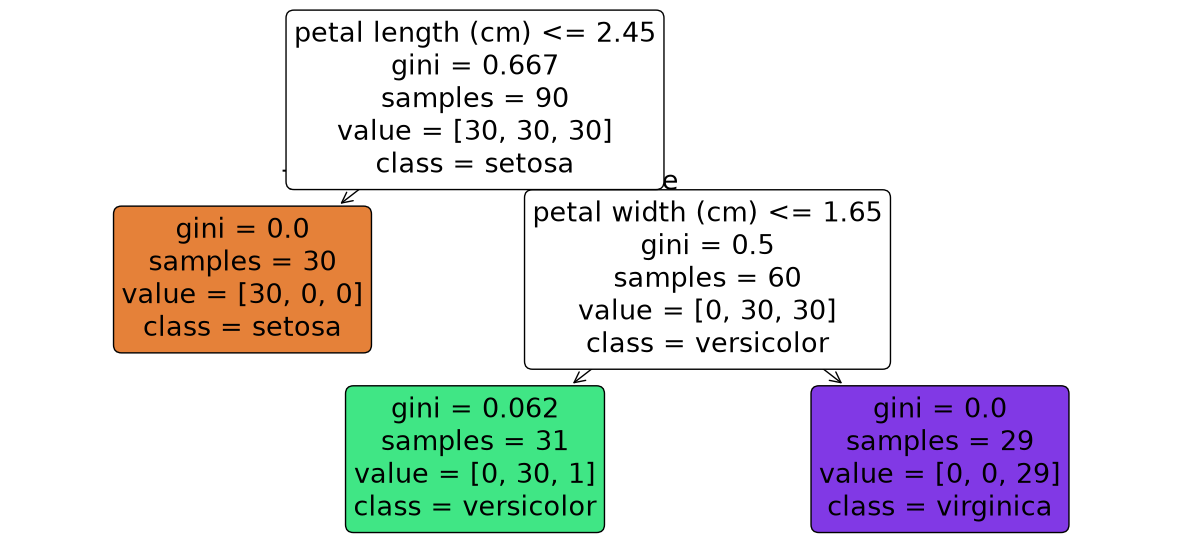

sepal length (cm)    6.7
sepal width (cm)     3.3
petal length (cm)    5.7
petal width (cm)     2.5
Name: Validation sample, dtype: float64

Model prediction: virginica
True species: virginica


In [13]:

plt.figure(figsize=(15, 7))

plot_tree(
    baseline,
    feature_names=feature_names,
    class_names=list(class_names),
    filled=True,
    rounded=True
)

plt.show()

sample_index = 0

display(
    pd.Series(
        X_val[sample_index],
        index=feature_names,
        name='Validation sample'
    )
)

print(
    'Model prediction:',
    class_names[baseline.predict(X_val[[sample_index]])[0]]
)

print('True species:', class_names[y_val[sample_index]])


### Question 3
For validation sample 0, write the complete path from root to leaf: feature, threshold, and left/right direction at each decision. Does your predicted class match the model output?

**Your answer:**

[Write your answer here.]

## Task 5 — Investigate max_depth
Before running: predict what increasing depth will do. Keep `criterion="gini"` and all other settings fixed. Record training accuracy, validation accuracy, actual depth, and leaf count. `max_depth` is an upper limit: a tree may stop earlier when a node is pure or another stopping condition is met.

**Code hint T5:** the loop variable `depth` is the current parameter value. Evaluate on validation data, not test data.

,max_depth,train_accuracy,val_accuracy,actual_depth,leaves
0,1,0.666667,0.666667,1,2
1,2,0.988889,0.900000,2,3
2,3,0.988889,0.900000,3,4
3,4,1.000000,0.933333,4,5
4,5,1.000000,0.933333,4,5


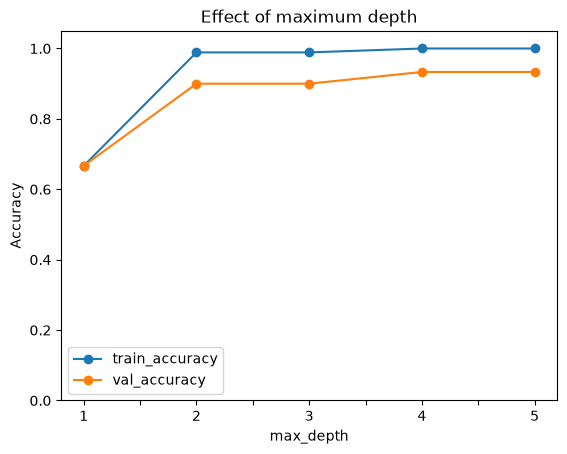

In [14]:

depths = [1, 2, 3, 4, 5]
depth_rows = []

for depth in depths:
    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    depth_rows.append({
        'max_depth': str(depth),
        'train_accuracy': model.score(X_train, y_train),
        'val_accuracy': model.score(X_val, y_val),
        'actual_depth': model.get_depth(),
        'leaves': model.get_n_leaves()
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results)

depth_results.plot(
    x='max_depth',
    y=['train_accuracy', 'val_accuracy'],
    marker='o',
    ylim=(0, 1.05),
    ylabel='Accuracy',
    title='Effect of maximum depth'
)

plt.show()


### Question 4
As max_depth increases from 1 to 5, how do training Accuracy, validation Accuracy, and the number of leaves change? Is a deeper tree always better? Cite your results.

**Your answer:**

[Write your answer here.]

### Compare tree structures
The plotting code is provided. Compare depths 1, 2, and 4.

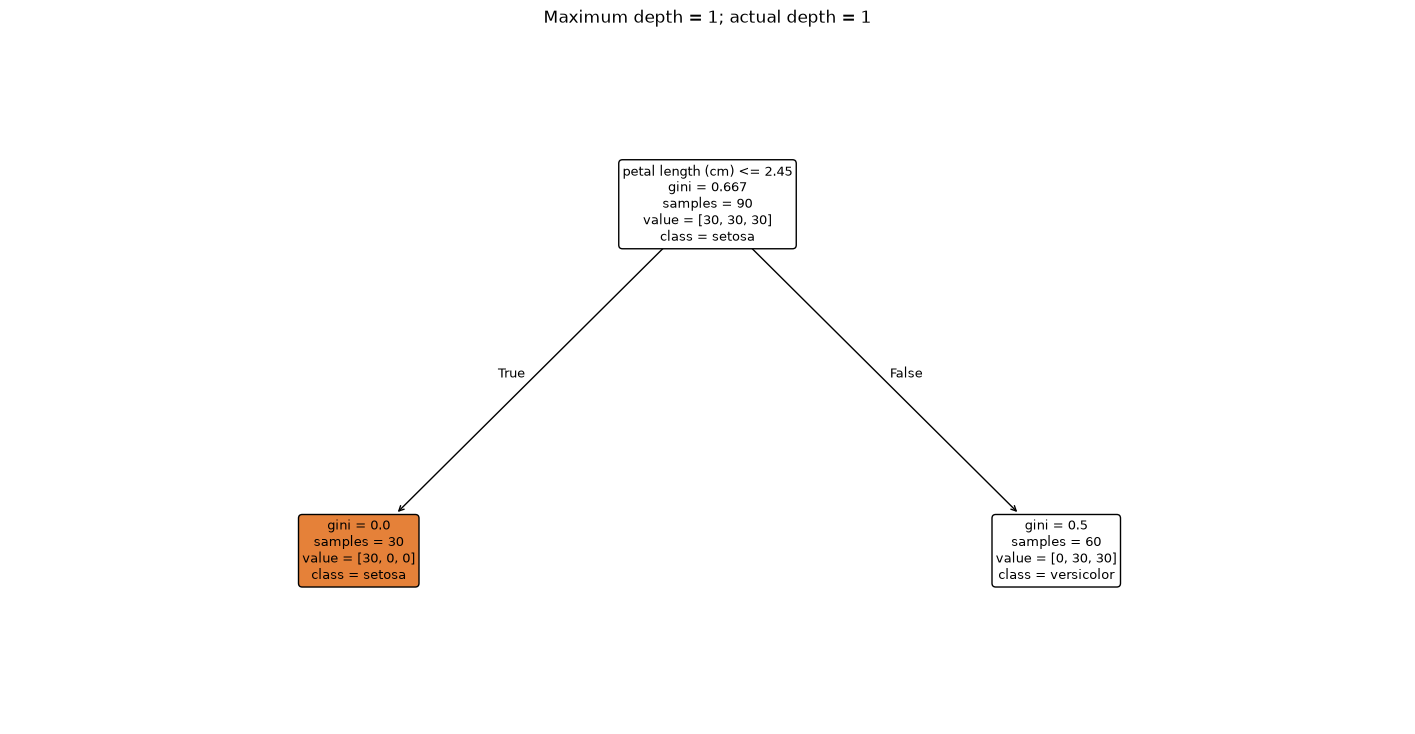

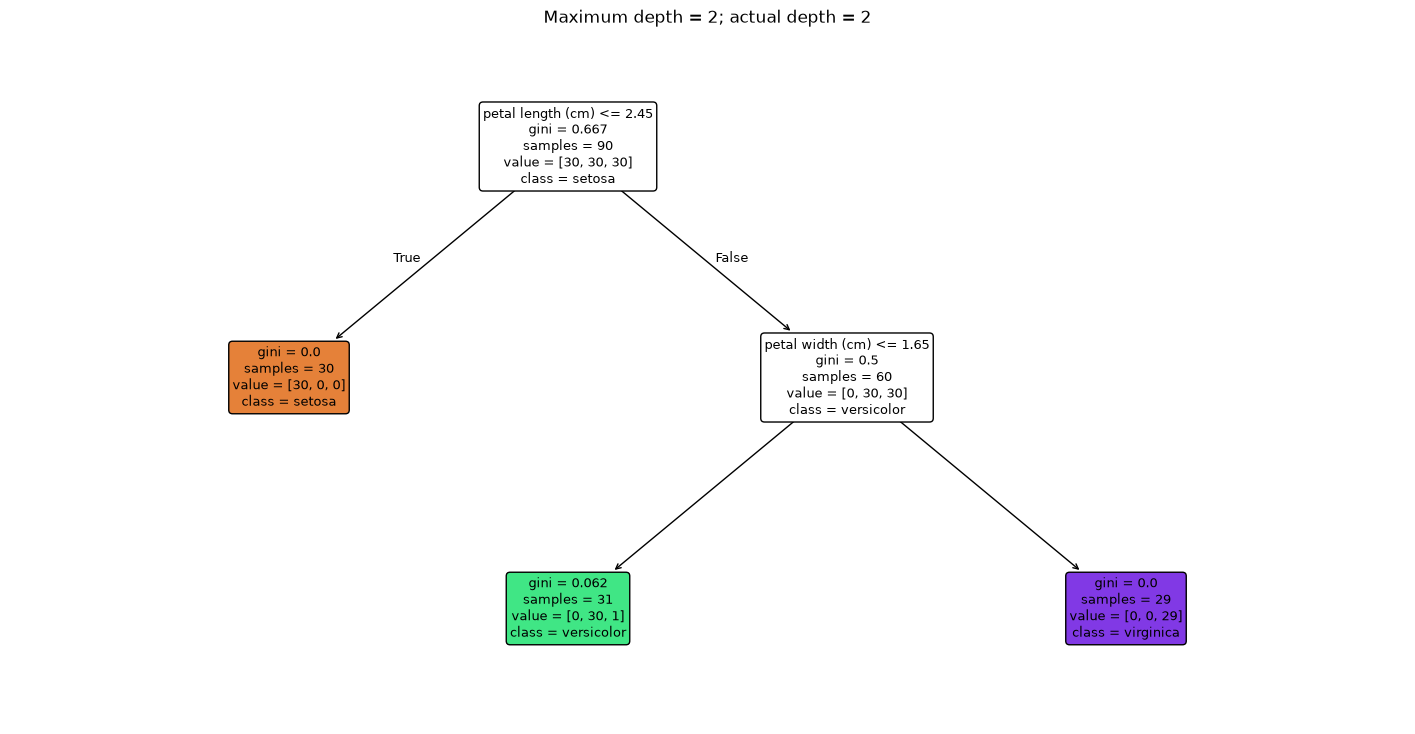

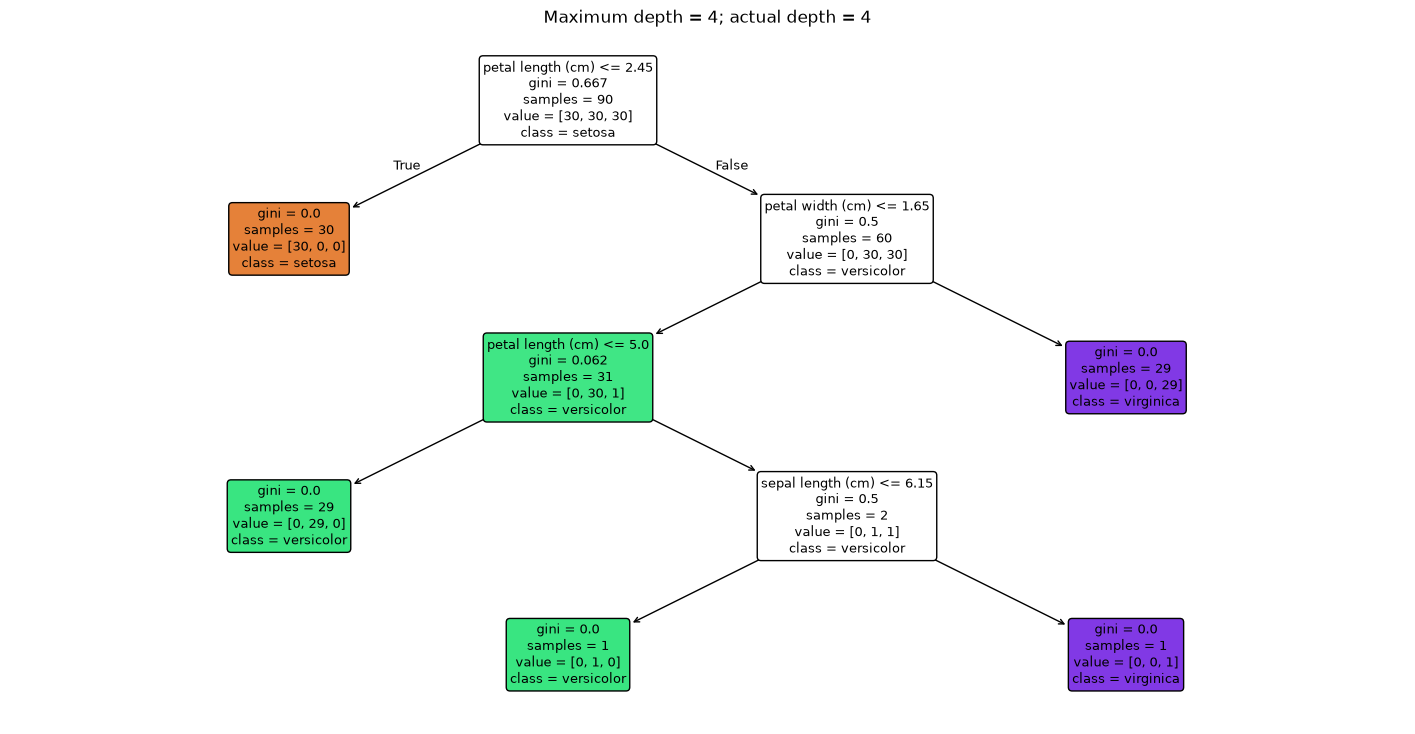

In [15]:
for depth in [1, 2, 4]:
    tree = DecisionTreeClassifier(criterion='gini', max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    plt.figure(figsize=(18, 9))
    plot_tree(tree, feature_names=feature_names, class_names=list(class_names),
              filled=True, rounded=True, fontsize=9)
    plt.title(f'Maximum depth = {depth}; actual depth = {tree.get_depth()}')
    plt.show()

## Task 6 — Compare Gini and Entropy
Fix `max_depth=3`. Gini impurity is `1 - sum(p_k**2)`; entropy is `-sum(p_k * log2(p_k))`, with a zero contribution when `p_k=0`. Both measure class mixture, and the algorithm seeks splits that reduce weighted impurity. Their numerical values use different scales, so a smaller raw Gini number does not establish a better model.

**Code hint T6:** pass the loop variable `criterion` to the parameter with the same name.

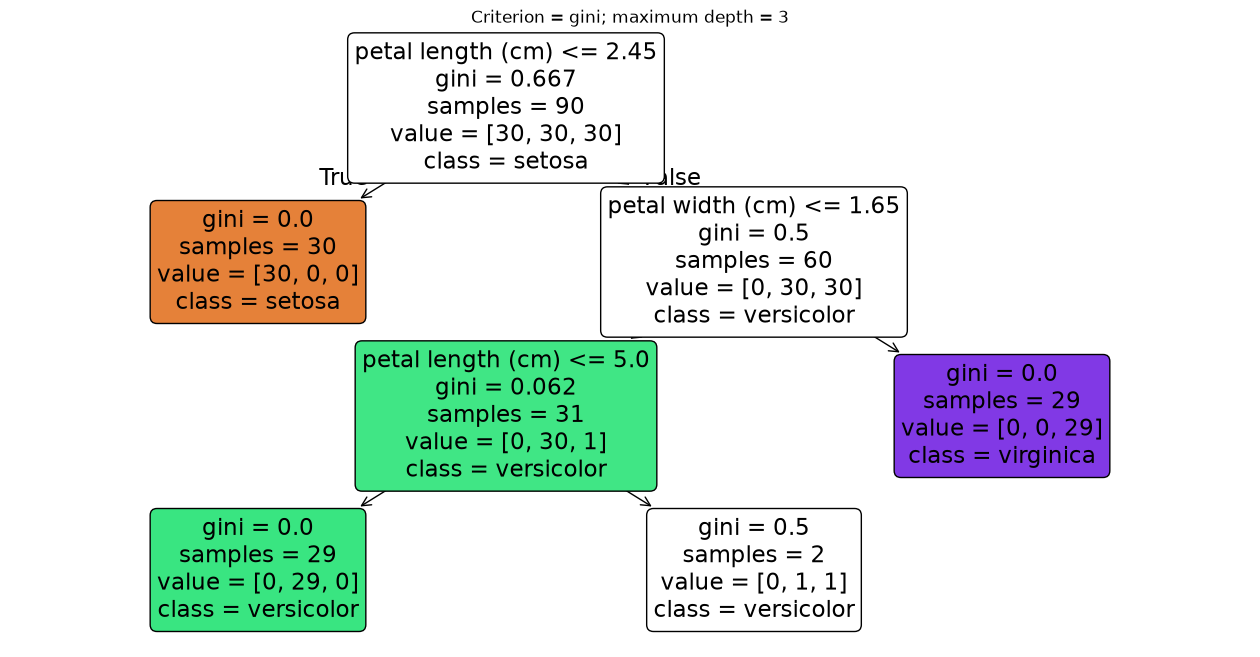

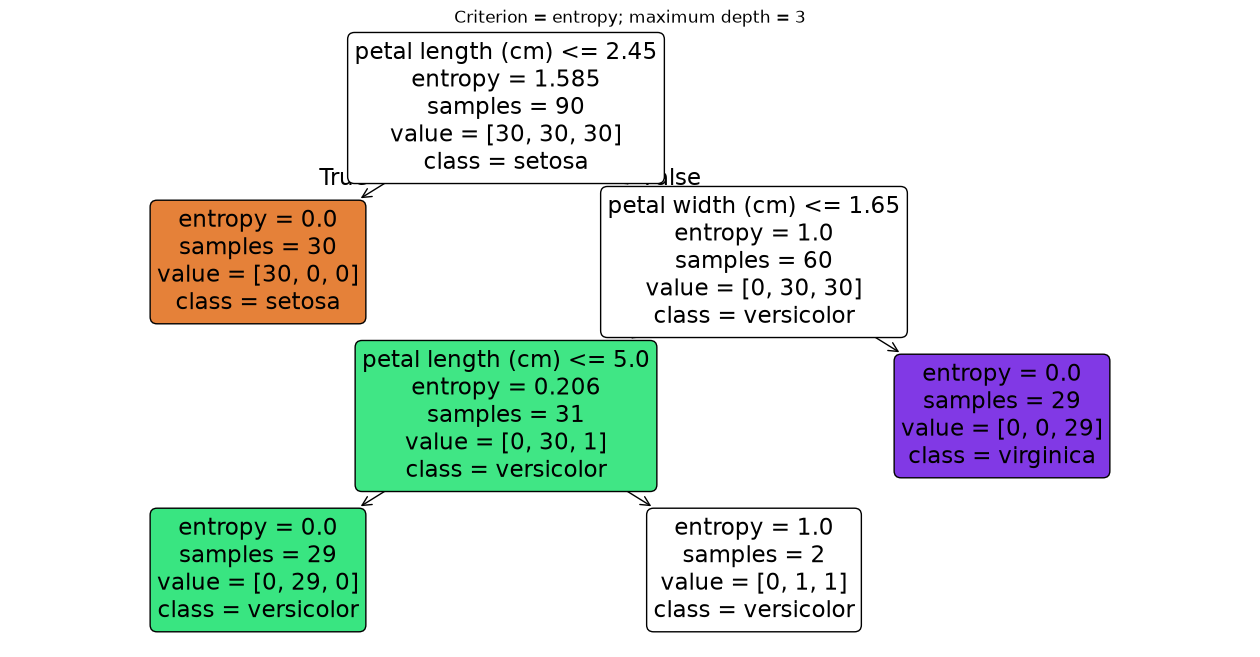

,criterion,train_accuracy,val_accuracy,actual_depth,leaves
0,gini,0.988889,0.9,3,4
1,entropy,0.988889,0.9,3,4


In [16]:

criteria = ['gini', 'entropy']
criterion_rows = []

for criterion in criteria:
    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    criterion_rows.append({
        'criterion': criterion,
        'train_accuracy': model.score(X_train, y_train),
        'val_accuracy': model.score(X_val, y_val),
        'actual_depth': model.get_depth(),
        'leaves': model.get_n_leaves()
    })

    plt.figure(figsize=(16, 8))

    plot_tree(
        model,
        feature_names=feature_names,
        class_names=list(class_names),
        filled=True,
        rounded=True
    )

    plt.title(f'Criterion = {criterion}; maximum depth = 3')
    plt.show()

criterion_results = pd.DataFrame(criterion_rows)
display(criterion_results)


### Question 5
With max_depth fixed at 3, do Gini and Entropy produce different tree structures or validation Accuracy? Support your answer with the output.

**Your answer:**

[Write your answer here.]

## Task 7 — Joint parameter tuning with Grid Search
Tasks 5–6 changed one parameter at a time. Now compare all 10 combinations: 2 criteria × 5 depth settings.

Use **5-fold stratified cross-validation on the development set**. Each configuration is fitted five times, each time training on four folds and validating on the remaining fold. There are 50 cross-validation fits. For each configuration, every development flower is used for validation once. The final test set is never passed to the search.

`scoring='accuracy'` selects the prediction-performance metric. `refit=True` chooses the configuration with the highest mean cross-validation Accuracy, then trains it again on all 120 development flowers. This adds **one final refit**.

Tied or close scores are valid outcomes. Do not assume that each configuration must have a different score.

**Code hint T7:** `param_grid` maps parameter names to candidate lists. Use `X_dev, y_dev` in `.fit()`. If the highest scores tie, GridSearchCV selects the first tied candidate in its candidate order. This does not guarantee the simplest tree or a unique winner.

In [17]:

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [1, 2, 3, 4, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    refit=True,
    cv=cv,
    return_train_score=True,
    error_score='raise'
)

search.fit(X_dev, y_dev)

print('Selected parameters:', search.best_params_)
print('Best mean CV Accuracy:', search.best_score_)

results = pd.DataFrame(search.cv_results_)

summary = results[
    [
        'param_criterion',
        'param_max_depth',
        'mean_train_score',
        'mean_test_score',
        'rank_test_score'
    ]
].rename(columns={
    'mean_train_score': 'mean_train_accuracy',
    'mean_test_score': 'mean_cv_accuracy',
    'rank_test_score': 'rank_cv_accuracy'
})

display(
    summary.sort_values(
        'rank_cv_accuracy',
        kind='stable'
    ).reset_index(drop=True)
)


Selected parameters: {'criterion': 'gini', 'max_depth': 3}
Best mean CV Accuracy: 0.9583333333333334


,param_criterion,param_max_depth,mean_train_accuracy,mean_cv_accuracy,rank_cv_accuracy
0,gini,3,0.979167,0.958333,1
1,gini,5,0.997917,0.950000,2
2,entropy,3,0.979167,0.950000,2
3,entropy,5,0.995833,0.941667,4
4,gini,2,0.966667,0.941667,5
5,gini,4,0.993750,0.941667,5
6,entropy,2,0.966667,0.941667,5
7,entropy,4,0.989583,0.933333,8
8,gini,1,0.666667,0.666667,9
9,entropy,1,0.666667,0.666667,9


**Reading the results:** With one scoring metric, `mean_test_score` is the mean validation Accuracy across cross-validation folds, and `rank_test_score` ranks the candidates by this mean. Here, "test" refers to internal validation folds, not the final held-out test set. The table renames these columns to `mean_cv_accuracy` and `rank_cv_accuracy`.

### Question 6
**Did parameter tuning improve the model?** Before the final test, compare the baseline configuration (`criterion='gini'`, `max_depth=2`) with the configuration selected by Grid Search, using the same five cross-validation folds.

| Model | criterion | max_depth | Mean CV Accuracy |
|---|---|---|---|
| Baseline configuration | gini | 2 | ... |
| Grid Search selection | ... | ... | ... |

How many percentage points did the selected model improve over the baseline? If there was no improvement, state this clearly.

Read both scores from the Grid Search results: the baseline configuration is already one of the ten candidates. Do not use its earlier single-split validation Accuracy. Calculate the increase as `(selected mean CV Accuracy - baseline mean CV Accuracy) * 100`. No additional model training is required.

**Your answer:**

[Write your answer here.]

## Task 8 — Evaluate the selected model once
`search.best_estimator_` has already been refitted on all development data. Use it directly. Do not fit it again on the smaller initial training subset, and do not change parameters after inspecting the test result.

Complete three fill-in activities: retrieve the selected refitted model, predict the test labels, and calculate test Accuracy. The output table is provided.

**Code hint T8:** retrieve the model from a search attribute rather than calling `.fit()` again. `.predict(features)` produces predicted labels. `accuracy_score(true_labels, predicted_labels)` gives the fraction of correctly classified test flowers. `np.sum(test_pred != y_test)` counts errors.

In [18]:

final_model = search.best_estimator_

test_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_pred)

display(pd.DataFrame([{
    'test_accuracy': test_accuracy,
    'correct': int(np.sum(test_pred == y_test)),
    'misclassified': int(np.sum(test_pred != y_test)),
    'test_samples': len(y_test),
    'actual_depth': final_model.get_depth(),
    'leaves': final_model.get_n_leaves()
}]))


,test_accuracy,correct,misclassified,test_samples,actual_depth,leaves
0,0.966667,29,1,30,3,5


## Submission checklist
- Complete all TODO blanks; restart the kernel and run all cells in order.
- Save the result tables, Accuracy plot, tree visualizations, and final test output.
- Answer Questions 1–6 in Markdown cells. Use saved outputs as evidence; only Question 6 needs a short record table.
- Record the selected model before final test evaluation.
- Do not retune using the final test result.

Submit one file named `Lab1_DecisionTree_StudentID.ipynb`. No separate report is required.

Keep the final test output. No additional written test-result table or separate experiment summary is required.